# 05 — Scaling: how fast is FinBERT, and what would 1000× more data take?

The brief asks us to (b) "learn about the computational performance of the model(s)" and to argue how the approach
would work "if the data volume were to increase by a factor of 1000", benefiting "efficiently" from GPUs or clusters.

Our pipeline has two neural steps with very different costs:

1. **FinBERT reads every chunk of every report** (`extract_finbert.py`). This is a big pre-trained network
   (110 million parameters) run once over all the text.
2. **The attention network is trained on FinBERT's saved output** (`Alex/03-Attention-network.ipynb`). This is small and
   is re-trained many times (seeds, test years, windows).

This notebook measures step 1 on this laptop (Apple M3, 8 GB), and uses the throughput Alex measured for step 2.

| Section | Question |
|---|---|
| 1 | How big is our workload, in reports, chunks and bytes? |
| 2 | How fast is FinBERT on CPU vs GPU, at full vs half precision, at different batch sizes? |
| 3 | Does the time grow in proportion to the amount of data? |
| 4 | What would 1000× take, and does it split across many GPUs efficiently? |

Run from the `Oscar/` folder with the shared venv. Sections 2–3 take about 5–10 minutes. FinBERT must be in the
Hugging Face cache (it is after running `extract_finbert.py`), and `data/processed/` must exist (`report/02-Data.ipynb`).

In [1]:
import gc
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers

sys.path.insert(0, str(Path.cwd()))   # so we can reuse the functions in extract_finbert.py
from extract_finbert import CHUNK, MODEL, load_model, load_plan, load_texts

transformers.logging.set_verbosity_error()   # hide the "sequence longer than 512" warning: we chunk it ourselves
ROOT = Path("..")
PROCESSED = ROOT / "data" / "processed"

DEVICES = ["cpu"] + (["mps"] if torch.backends.mps.is_available() else []) + (["cuda"] if torch.cuda.is_available() else [])
GPU = DEVICES[-1] if len(DEVICES) > 1 else None
print("torch", torch.__version__, "| devices:", DEVICES)

torch 2.15.0 | devices: ['cpu', 'mps']


## 1. The size of our workload

`dataset.csv` has one row per report, with the number of FinBERT chunks for Item 1 and Item 7.
`_n` is the number of chunks we kept (at most 64 per section) and `_true` the number the full text would need.
Each chunk becomes 768 numbers stored at half precision (2 bytes each), so 1,536 bytes per chunk.

In [2]:
ds = pd.read_csv(PROCESSED / "dataset.csv")
ds["chunks"] = ds["item1_n"] + ds["item7_n"]
ds["chunks_true"] = ds["item1_true"] + ds["item7_true"]

BYTES_PER_VECTOR = 768 * 2   # float16
workload = pd.Series({
    "reports": len(ds),
    "chunks kept (Item 1 + Item 7)": ds["chunks"].sum(),
    "chunks if nothing were cut at 64": ds["chunks_true"].sum(),
    "median chunks per report": ds["chunks"].median(),
    "saved FinBERT output (GB)": ds["chunks"].sum() * BYTES_PER_VECTOR / 1e9,
})
print(workload.to_string(float_format="{:,.2f}".format))

# check the arithmetic against the real files on disk
on_disk = sum((PROCESSED / f).stat().st_size for f in ["item1_emb.npy", "item7_emb.npy"]) / 1e9
print(f"\nactual size of item1_emb.npy + item7_emb.npy: {on_disk:.2f} GB")

reports                             27,142.00
chunks kept (Item 1 + Item 7)      943,001.00
chunks if nothing were cut at 64   947,164.00
median chunks per report                32.00
saved FinBERT output (GB)                1.45

actual size of item1_emb.npy + item7_emb.npy: 1.45 GB


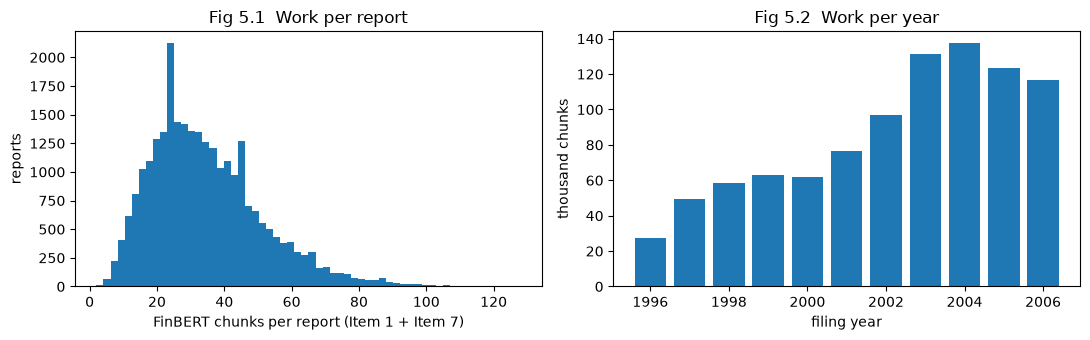

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(ds["chunks"], bins=60, color="tab:blue")
ax[0].set(xlabel="FinBERT chunks per report (Item 1 + Item 7)", ylabel="reports", title="Fig 5.1  Work per report")
per_year = ds.groupby("year")["chunks"].sum() / 1e3
ax[1].bar(per_year.index, per_year.values, color="tab:blue")
ax[1].set(xlabel="filing year", ylabel="thousand chunks", title="Fig 5.2  Work per year")
plt.tight_layout(); plt.show()

## 2. Experiment A: device, precision and batch size

We take real chunks from 2006 reports (Item 1 and Item 7, cut exactly as `extract_finbert.py` does), and time how
many chunks per second FinBERT processes under each setting:

- **device**: CPU vs the Mac's GPU (`mps`; on Colab this would be `cuda`);
- **precision**: 32-bit numbers (`fp32`) vs 16-bit (`fp16`, what the full run used, after `extract_finbert.py --smoke`
  checked that fp16 and fp32 give near-identical vectors). Half precision is GPU-only here;
- **batch size**: how many chunks go through the network at once. Bigger batches keep the GPU busier, until memory runs out.

Each setting is timed twice and we keep the faster run (the slower one is usually disturbed by something else on the
machine), after one warm-up batch, because the first call to a GPU is slow while it compiles.

We also time the **tokeniser** (turning text into FinBERT's word pieces), which runs on the CPU. If it were slower than
FinBERT it would be the bottleneck, and adding GPUs would not help.

In [4]:
plan = load_plan()
rows = plan[plan["year"] == 2006].head(150)
texts = load_texts(2006, rows)
docs = [t for k in rows["key"] for t in texts[k] if t]

tok = transformers.AutoTokenizer.from_pretrained(MODEL)
t0 = time.perf_counter()
ids = [tok(d, add_special_tokens=False)["input_ids"] for d in docs]
tok_secs = time.perf_counter() - t0

chunks = [x[i:i + CHUNK] for x in ids for i in range(0, len(x), CHUNK)]
text_bytes = sum(len(d.encode("utf-8")) for d in docs)
BYTES_TEXT_PER_CHUNK = text_bytes / len(chunks)
print(f"{len(docs)} sections from {len(rows)} reports -> {len(chunks):,} chunks")
print(f"tokeniser: {len(chunks) / tok_secs:,.0f} chunks/s on one CPU core")
print(f"raw text: about {BYTES_TEXT_PER_CHUNK / 1e3:.1f} kB per chunk")

300 sections from 150 reports -> 5,638 chunks
tokeniser: 1,449 chunks/s on one CPU core
raw text: about 2.6 kB per chunk


In [5]:
def sync(device):
    if device == "mps":
        torch.mps.synchronize()
    elif device == "cuda":
        torch.cuda.synchronize()


def time_forward(model, chunks, device, batch):
    # Seconds for FinBERT to turn `chunks` into CLS vectors, batched as in extract_finbert.embed()
    sync(device)
    t = time.perf_counter()
    with torch.inference_mode():
        for i in range(0, len(chunks), batch):
            enc = tok.pad({"input_ids": [[tok.cls_token_id] + c + [tok.sep_token_id] for c in chunks[i:i + batch]]},
                          return_tensors="pt")
            out = model(**{k: v.to(device) for k, v in enc.items()}).last_hidden_state[:, 0]
            out.float().cpu()
    sync(device)
    return time.perf_counter() - t


def free(model, device):
    del model
    gc.collect()
    if device == "mps":
        torch.mps.empty_cache()
    elif device == "cuda":
        torch.cuda.empty_cache()


# (device, precision, batch sizes, number of chunks to time). The CPU is slow, so it gets fewer chunks.
configs = [("cpu", torch.float32, [1, 8, 32], 64)]
if GPU:
    configs += [(GPU, torch.float32, [1, 8, 32, 64], 256), (GPU, torch.float16, [1, 8, 32, 64], 256)]

results, load_secs = [], {}
for device, dtype, batches, n in configs:
    t = time.perf_counter()
    _, model = load_model(device, dtype)
    sync(device)
    load_secs[(device, str(dtype))] = time.perf_counter() - t
    time_forward(model, chunks[:8], device, 8)                     # warm-up
    for b in batches:
        secs = min(time_forward(model, chunks[:n], device, b) for _ in range(2))
        results.append({"device": device, "precision": str(dtype).replace("torch.float", "fp"),
                        "batch": b, "chunks": n, "seconds": secs, "chunks_per_s": n / secs})
        print(results[-1])
    free(model, device)

speed = pd.DataFrame(results)
speed.to_csv(PROCESSED / "scaling_speed.csv", index=False)
print("\nmodel load time (s):", {k: round(v, 1) for k, v in load_secs.items()})

W1116 15:54:06.376000 23634 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'device': 'cpu', 'precision': 'fp32', 'batch': 1, 'chunks': 64, 'seconds': 11.733172917000047, 'chunks_per_s': 5.454620029273684}


{'device': 'cpu', 'precision': 'fp32', 'batch': 8, 'chunks': 64, 'seconds': 17.66586583299795, 'chunks_per_s': 3.6228057319701157}


{'device': 'cpu', 'precision': 'fp32', 'batch': 32, 'chunks': 64, 'seconds': 14.428255833001458, 'chunks_per_s': 4.435740587134177}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (5 outputs left out)

{'device': 'mps', 'precision': 'fp16', 'batch': 1, 'chunks': 256, 'seconds': 10.22959450000053, 'chunks_per_s': 25.02542989362743}


{'device': 'mps', 'precision': 'fp16', 'batch': 8, 'chunks': 256, 'seconds': 9.817870792001486, 'chunks_per_s': 26.074900090206977}


{'device': 'mps', 'precision': 'fp16', 'batch': 32, 'chunks': 256, 'seconds': 9.761357667000993, 'chunks_per_s': 26.225860042545857}


{'device': 'mps', 'precision': 'fp16', 'batch': 64, 'chunks': 256, 'seconds': 9.858004541998525, 'chunks_per_s': 25.96874437512694}

model load time (s): {('cpu', 'torch.float32'): 2.0, ('mps', 'torch.float32'): 1.5, ('mps', 'torch.float16'): 1.3}


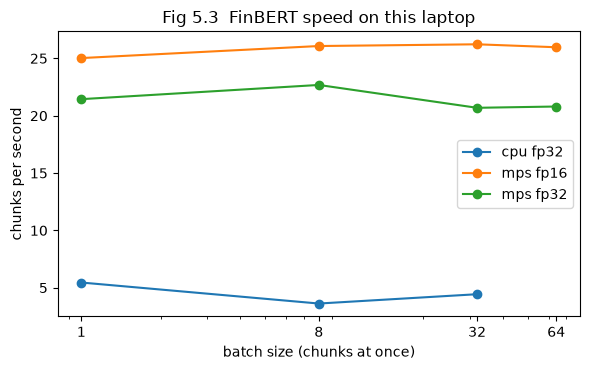

device     cpu   mps      
precision fp32  fp16  fp32
batch                     
1          5.5  25.0  21.4
8          3.6  26.1  22.7
32         4.4  26.2  20.7
64         NaN  26.0  20.8

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.8))
for (device, prec), g in speed.groupby(["device", "precision"]):
    ax.plot(g["batch"], g["chunks_per_s"], "o-", label=f"{device} {prec}")
ax.set(xscale="log", xlabel="batch size (chunks at once)", ylabel="chunks per second",
       title="Fig 5.3  FinBERT speed on this laptop")
ax.set_xticks([1, 8, 32, 64], labels=["1", "8", "32", "64"])
ax.legend(); plt.tight_layout(); plt.show()

pivot = speed.pivot_table(index="batch", columns=["device", "precision"], values="chunks_per_s").round(1)
pivot

## 3. Experiment B: does the time grow in proportion to the data?

If FinBERT's time is a fixed start-up cost plus a constant cost per chunk, then `time = a + b × chunks`, and the
1000× estimate is just that line extended. We time 32 up to 1,024 chunks with the setting the full run used
(GPU, fp16, batch 32) and fit the line by least squares.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

time = -0.11 s + 39.3 ms per chunk   (R² = 0.9999)
=> 25.4 chunks/s on mps torch.float16


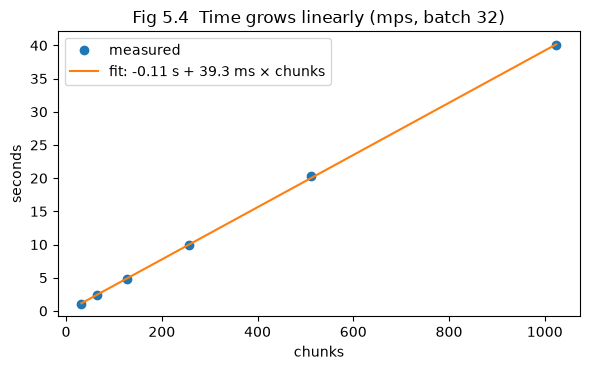

In [7]:
device = GPU or "cpu"
dtype = torch.float16 if GPU else torch.float32
batch = 32
sizes = [n for n in [32, 64, 128, 256, 512, 1024] if n <= len(chunks)]
if not GPU:
    sizes = sizes[:4]   # the CPU is too slow for the big sizes

_, model = load_model(device, dtype)
time_forward(model, chunks[:8], device, 8)
grow = pd.DataFrame({"chunks": sizes, "seconds": [time_forward(model, chunks[:n], device, batch) for n in sizes]})
free(model, device)

b, a = np.polyfit(grow["chunks"], grow["seconds"], 1)
pred = a + b * grow["chunks"]
r2 = 1 - ((grow["seconds"] - pred) ** 2).sum() / ((grow["seconds"] - grow["seconds"].mean()) ** 2).sum()
RATE = 1 / b   # chunks per second, once the fixed cost is paid
print(f"time = {a:.2f} s + {b * 1000:.1f} ms per chunk   (R² = {r2:.4f})")
print(f"=> {RATE:.1f} chunks/s on {device} {dtype}")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(grow["chunks"], grow["seconds"], "o", label="measured")
ax.plot(grow["chunks"], pred, "-", label=f"fit: {a:.2f} s + {b * 1000:.1f} ms × chunks")
ax.set(xlabel="chunks", ylabel="seconds", title=f"Fig 5.4  Time grows linearly ({device}, batch {batch})")
ax.legend(); plt.tight_layout(); plt.show()

The fitted start-up cost `a` comes out at about zero (it can even be slightly negative, which just means it is too
small to measure against the timing noise). So FinBERT's cost is, to a very good approximation, **a fixed price per chunk**.
As a check, 943,001 chunks at this rate predicts about 11 hours, which matches how long the full
`extract_finbert.py` run took on this laptop.

## 4. What 1000× would take

**Assumptions** (each one is stated so it can be challenged):

- 1000× more data means 1000× as many reports, each with the same number of chunks as ours. (1000× our corpus is
  about 27 million reports, more 10-Ks than have ever been filed, so in practice it would mean adding other text:
  8-Ks, earnings-call transcripts, news.)
- FinBERT runs at the rate measured in Section 3. A data-centre GPU would be faster, so these times are an upper bound
  per GPU.
- Training speed of the attention network is **Alex's measurement**: 1,641 reports per second on CPU, Item 7 only,
  batch 64 (`Alex/03-Attention-network.ipynb`, section 5). It is a different machine and a different model from
  FinBERT, so it is only a rough comparison.

In [8]:
TRAIN_RATE = 1641          # reports/s, attention network, from Alex/03-Attention-network.ipynb section 5
reports, n_chunks = len(ds), ds["chunks"].sum()

rows_ = []
for scale in [1, 1000]:
    c = n_chunks * scale
    rows_.append({
        "scale": f"{scale}×",
        "reports": reports * scale,
        "chunks": c,
        "raw text (GB)": c * BYTES_TEXT_PER_CHUNK / 1e9,
        "FinBERT output (GB)": c * BYTES_PER_VECTOR / 1e9,
        "FinBERT on 1 laptop GPU (days)": c / RATE / 86400,
        "1 epoch of attention net (minutes)": reports * scale / TRAIN_RATE / 60,
    })
scale_table = pd.DataFrame(rows_).set_index("scale")
scale_table.style.format("{:,.1f}")

,reports,chunks,raw text (GB),FinBERT output (GB),FinBERT on 1 laptop GPU (days),1 epoch of attention net (minutes)
scale,,,,,,
1×,"27,142.0","943,001.0",2.4,1.4,0.4,0.3
1000×,"27,142,000.0","943,001,000.0","2,421.0","1,448.4",429.3,275.7


### Map/reduce: does FinBERT split across many GPUs efficiently?

Every chunk is read independently: no chunk needs another chunk's result. So the reading step is a **map**: give each of
`N` GPUs `1/N` of the chunks. The **reduce** step only collects each report's chunk vectors together, which is
bookkeeping (what `build_dataset.py` does in seconds).

Two costs do **not** shrink as we add GPUs:

- each worker loads FinBERT once (measured in Section 2, about a second);
- the raw text has to be **read from storage and sent to the workers**. If it all comes from one shared store, that
  store's bandwidth is a fixed limit however many GPUs are waiting. We **assume** 1 GB/s (`BANDWIDTH_GB_S`, change it to
  test). This is not measured: it is a round number for one shared network drive.

So with `N` workers

    time(N) = start-up + text size / bandwidth + chunks / (N × rate)

and the **efficiency** (how close we get to `N` times faster) is `time(1) / (N × time(N))`. This is Amdahl's law:
the part that cannot be split eventually dominates.

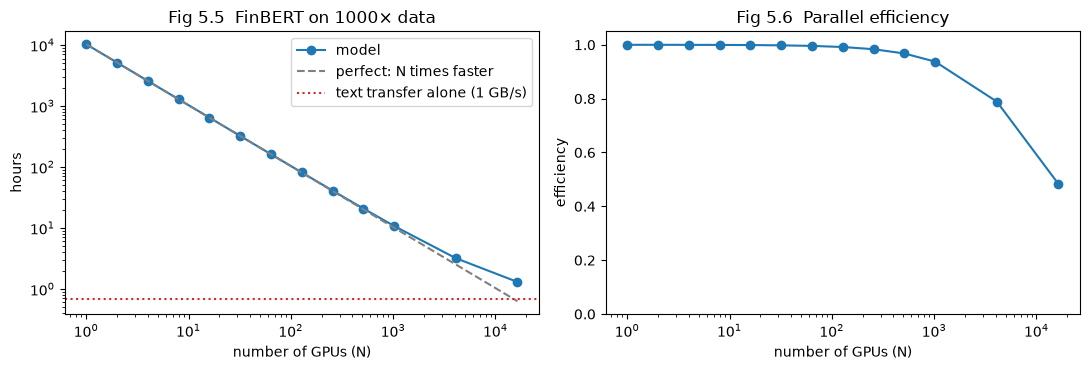

start-up per worker: 1.3 s;  moving 2.4 TB of text: 0.67 h
 GPUs     hours  efficiency
    1 10,302.93        1.00
    2  5,151.80        1.00
    4  2,576.24        1.00
    8  1,288.45        1.00
   16    644.56        1.00
   32    322.62        1.00
   64    161.65        1.00
  128     81.16        0.99
  256     40.92        0.98
  512     20.79        0.97
 1024     10.73        0.94
 4096      3.19        0.79
16384      1.30        0.48


In [9]:
BANDWIDTH_GB_S = 1.0       # ASSUMED, not measured: one shared store feeding every worker
startup = load_secs.get((device, str(dtype)), 5.0)
c = n_chunks * 1000
transfer = c * BYTES_TEXT_PER_CHUNK / 1e9 / BANDWIDTH_GB_S
N = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 4096, 16384])
t_N = startup + transfer + c / (N * RATE)
eff = t_N[0] / (N * t_N)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].loglog(N, t_N / 3600, "o-", label="model")
ax[0].loglog(N, t_N[0] / N / 3600, "--", color="grey", label="perfect: N times faster")
ax[0].axhline(transfer / 3600, color="tab:red", ls=":", label=f"text transfer alone ({BANDWIDTH_GB_S:g} GB/s)")
ax[0].set(xlabel="number of GPUs (N)", ylabel="hours", title="Fig 5.5  FinBERT on 1000× data")
ax[0].legend()
ax[1].semilogx(N, eff, "o-")
ax[1].set(xlabel="number of GPUs (N)", ylabel="efficiency", ylim=(0, 1.05), title="Fig 5.6  Parallel efficiency")
plt.tight_layout(); plt.show()

print(f"start-up per worker: {startup:.1f} s;  moving {c * BYTES_TEXT_PER_CHUNK / 1e12:.1f} TB of text: {transfer / 3600:.2f} h")
print(pd.DataFrame({"GPUs": N, "hours": t_N / 3600, "efficiency": eff}).to_string(index=False, float_format="{:,.2f}".format))

## 5. What this shows

The headline numbers, computed from this run. The measured FinBERT rate varies by 10–20% between runs on the same
laptop (other programs, heat), so treat them as rough.

In [10]:
gpu = speed[speed["device"] != "cpu"]
cpu_rate = speed.loc[speed["device"] == "cpu", "chunks_per_s"].max()
fp16_gain = gpu.groupby("precision")["chunks_per_s"].max()
def eff_at(n):
    return eff[list(N).index(n)]
headline = pd.Series({
    "FinBERT rate, fitted (chunks/s)": f"{RATE:.1f}",
    "our corpus on the laptop GPU (hours)": f"{n_chunks / RATE / 3600:.1f}",
    "GPU vs CPU speed-up": f"{RATE / cpu_rate:.1f}x" if GPU else "no GPU",
    "fp16 vs fp32 on the GPU": f"{fp16_gain['fp16'] / fp16_gain['fp32'] - 1:+.0%}" if GPU else "no GPU",
    "1000x on one laptop GPU (days)": f"{c / RATE / 86400:,.0f}",
    "1000x FinBERT output (TB)": f"{c * BYTES_PER_VECTOR / 1e12:.2f}",
    "1000x on 1,024 GPUs (hours), efficiency": f"{t_N[list(N).index(1024)] / 3600:.1f}, {eff_at(1024):.0%}",
    "efficiency at 4,096 / 16,384 GPUs": f"{eff_at(4096):.0%} / {eff_at(16384):.0%}",
    "1000x, one attention-net epoch (hours, Alex's rate)": f"{reports * 1000 / TRAIN_RATE / 3600:.1f}",
})
print(headline.to_string())

FinBERT rate, fitted (chunks/s)                             25.4
our corpus on the laptop GPU (hours)                        10.3
GPU vs CPU speed-up                                         4.7x
fp16 vs fp32 on the GPU                                     +16%
1000x on one laptop GPU (days)                               429
1000x FinBERT output (TB)                                   1.45
1000x on 1,024 GPUs (hours), efficiency                10.7, 94%
efficiency at 4,096 / 16,384 GPUs                      79% / 48%
1000x, one attention-net epoch (hours, Alex's rate)          4.6


1. **FinBERT is the whole cost.** Reading our 27,142 reports takes about half a day on the laptop GPU; one epoch of the
   attention network on the saved output takes under a minute (Alex's rate). So scaling up is a question about the
   reading step.
2. **On this laptop, batch size barely matters and the GPU is only a few times faster than the CPU** (2.5–5× across our runs: the CPU speed varies most). One 512-token chunk is already
   enough work to fill the M3's small GPU, so batching more chunks adds nothing. On a data-centre GPU with far more
   cores, batching is what keeps it busy; that is worth testing on Colab (`cuda`).
3. **Half precision helps a little** at no measurable cost in accuracy (`extract_finbert.py --smoke`), and halves the
   storage of the output.
4. **Cost is linear in data**, with no measurable start-up cost, so 1000× data is 1000× the time: well over a year on one
   laptop GPU, and about 1.4 TB of FinBERT output.
5. **The reading step is a map with a trivial reduce**, so it splits across GPUs almost perfectly, to about 95%
   efficiency at 1,024 GPUs (half a day for 1000× data), until the GPUs are waiting on the storage that feeds them:
   with the assumed 1 GB/s, efficiency falls at a few thousand GPUs (Fig 5.6). Beyond that point the fix is to split the
   *data* too (each worker reads its own shard of filings from its own disk, as Spark or a sharded file store would),
   not to add more GPUs.
6. **Training does not need a cluster.** Even at 1000×, an epoch of the attention network is a few hours on one
   machine from Alex's CPU measurement, because it works on 768-number summaries, not text. If it did need splitting,
   data-parallel training (each GPU takes part of each batch and the gradients are averaged) suits a model this small.

Still to do: time FinBERT on a Colab GPU and add it as a row in Experiment A; time the attention network on the GPU
once its settings are agreed.